<a href="https://colab.research.google.com/github/Romanzilla/ML/blob/main/%D0%9B%D0%A011_%D0%9D%D0%B0%D0%B4%D1%96%D0%B9%D0%BA%D0%BE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 11
## Згорткові нейронні мережі (CNN) для розпізнавання дорожніх знаків

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Надійко Роман  
**Група:** ФІТ 3-10  
**Дата:** 17.11.2026  

**Мета:** побудувати та навчити згорткову нейронну мережу (CNN) для багатокласової класифікації дорожніх знаків на наборі даних **GTSRB (German Traffic Sign Recognition Benchmark)**, дослідити криві навчання та візуалізувати результати розпізнавання на тестових зображеннях.

In [1]:
import os
import cv2
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# Фіксація random seed для відтворюваності результатів
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Завантаження набору даних GTSRB із Kaggle
dataset_path = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
print("Шлях до завантаженого датасету:", dataset_path)
print("Вміст папки:", os.listdir(dataset_path))

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Шлях до завантаженого датасету: /kaggle/input/gtsrb-german-traffic-sign
Вміст папки: ['Meta', 'meta', 'Meta.csv', 'Train.csv', 'Test.csv', 'Test', 'test', 'Train', 'train']


In [2]:
IMG_SIZE = 32
NUM_CLASSES = 43

# Словник назв усіх 43 класів дорожніх знаків GTSRB
CLASS_NAMES = {
    0: 'Обмеження 20 км/год',
    1: 'Обмеження 30 км/год',
    2: 'Обмеження 50 км/год',
    3: 'Обмеження 60 км/год',
    4: 'Обмеження 70 км/год',
    5: 'Обмеження 80 км/год',
    6: 'Кінець обмеження 80 км/год',
    7: 'Обмеження 100 км/год',
    8: 'Обмеження 120 км/год',
    9: 'Обгін заборонено',
    10: 'Обгін вантажівкам заборонено',
    11: 'Перехрестя з другорядною дорогою',
    12: 'Головна дорога',
    13: 'Дати дорогу',
    14: 'Проїзд без зупинки заборонено (STOP)',
    15: 'Рух заборонено',
    16: 'Рух вантажівок заборонено',
    17: 'В’їзд заборонено',
    18: 'Інша небезпека',
    19: 'Небезпечний поворот ліворуч',
    20: 'Небезпечний поворот праворуч',
    21: 'Декілька поворотів',
    22: 'Нерівна дорога',
    23: 'Слизька дорога',
    24: 'Звуження дороги праворуч',
    25: 'Дорожні роботи',
    26: 'Світлофорне регулювання',
    27: 'Пішохідний перехід',
    28: 'Діти',
    29: 'Велосипедисти',
    30: 'Ожеледиця / сніг',
    31: 'Дикі тварини',
    32: 'Кінець усіх обмежень',
    33: 'Поворот праворуч',
    34: 'Поворот ліворуч',
    35: 'Рух прямо',
    36: 'Рух прямо або праворуч',
    37: 'Рух прямо або ліворуч',
    38: 'Об’їзд перешкоди праворуч',
    39: 'Об’їзд перешкоди ліворуч',
    40: 'Круговий рух',
    41: 'Кінець заборони обгону',
    42: 'Кінець заборони обгону вантажівкам'
}

def load_gtsrb_split(csv_filename):
    csv_path = os.path.join(dataset_path, csv_filename)
    df = pd.read_csv(csv_path)

    images = []
    labels = df['ClassId'].to_numpy(dtype=np.int32)

    for rel_path in df['Path']:
        full_img_path = os.path.join(dataset_path, rel_path)
        img = cv2.imread(full_img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        images.append(img)

    X = np.array(images, dtype=np.float32) / 255.0
    return X, labels

print("Завантаження та обробка зображень (зачекайте ~15–20 секунд)...")
X_train_full, y_train_full = load_gtsrb_split('Train.csv')
X_test, y_test = load_gtsrb_split('Test.csv')

# Відокремлення 20% навчальних даних під валідаційну вибірку
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    random_state=SEED,
    stratify=y_train_full
)

print(f"Навчальна вибірка (X_train):   {X_train.shape}, мітки: {y_train.shape}")
print(f"Валідаційна вибірка (X_val):   {X_val.shape}, мітки: {y_val.shape}")
print(f"Тестова вибірка (X_test):      {X_test.shape}, мітки: {y_test.shape}")
print(f"Діапазон значень пікселів:     [{X_train.min():.1f}; {X_train.max():.1f}]")

Завантаження та обробка зображень (зачекайте ~15–20 секунд)...
Навчальна вибірка (X_train):   (31367, 32, 32, 3), мітки: (31367,)
Валідаційна вибірка (X_val):   (7842, 32, 32, 3), мітки: (7842,)
Тестова вибірка (X_test):      (12630, 32, 32, 3), мітки: (12630,)
Діапазон значень пікселів:     [0.0; 1.0]


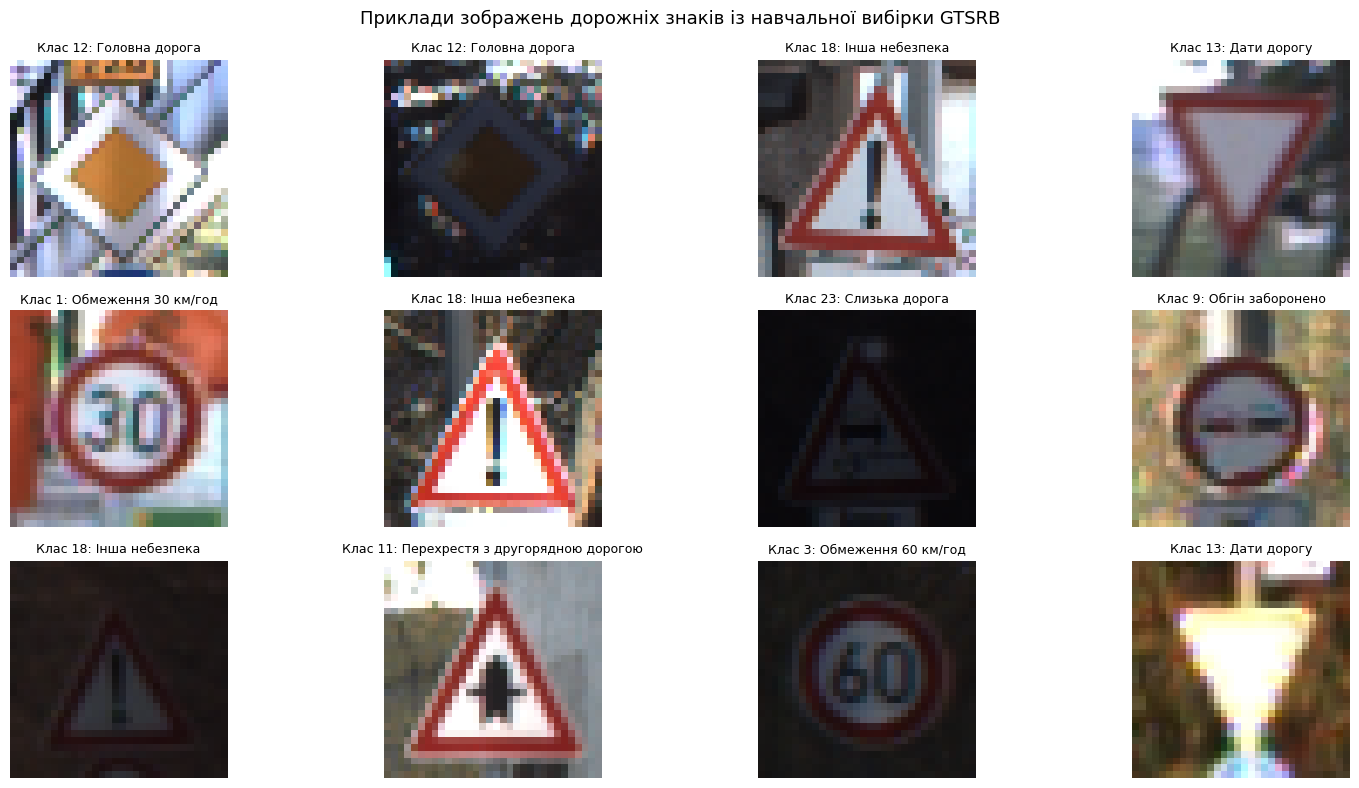

In [3]:
# Виведення 12 випадкових зображень із навчальної вибірки
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(X_train), size=12, replace=False)

plt.figure(figsize=(16, 8))
for i, idx in enumerate(sample_indices):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[idx])
    class_id = y_train[idx]
    plt.title(f"Клас {class_id}: {CLASS_NAMES[class_id]}", fontsize=9)
    plt.axis('off')

plt.suptitle("Приклади зображень дорожніх знаків із навчальної вибірки GTSRB", fontsize=13)
plt.tight_layout()
plt.show()

In [4]:
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    # Згортковий блок 1: виділення базових контурів, ліній та кольорів
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Згортковий блок 2: виділення складніших символів та форм знаків
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Повнозв’язний класифікатор
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation='softmax')
], name="GTSRB_CNN")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "GTSRB_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,127,243 (4.30 MB)

 Trainable params: 1,126,347 (4.30 MB)

 Non-trainable params: 896 (3.50 KB)

In [5]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=128,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 40s 94ms/step - accuracy: 0.7345 - loss: 1.0143 - val_accuracy: 0.3938 - val_loss: 2.2794 - learning_rate: 0.0010
Epoch 2/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9641 - loss: 0.1385 - val_accuracy: 0.9404 - val_loss: 0.2148 - learning_rate: 0.0010
Epoch 3/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9838 - loss: 0.0662 - val_accuracy: 0.9930 - val_loss: 0.0277 - learning_rate: 0.0010
Epoch 4/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9904 - loss: 0.0393 - val_accuracy: 0.9952 - val_loss: 0.0202 - learning_rate: 0.0010
Epoch 5/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9921 - loss: 0.0311 - val_accuracy: 0.9966 - val_loss: 0.0148 - learning_rate: 0.0010
Epoch 6/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.9952 - loss: 0.0204 - val_accuracy: 0.9960 - val_loss: 0.0161 - learning_rate: 0.0010
Epoch 7/20
242/246 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9953 - loss: 0

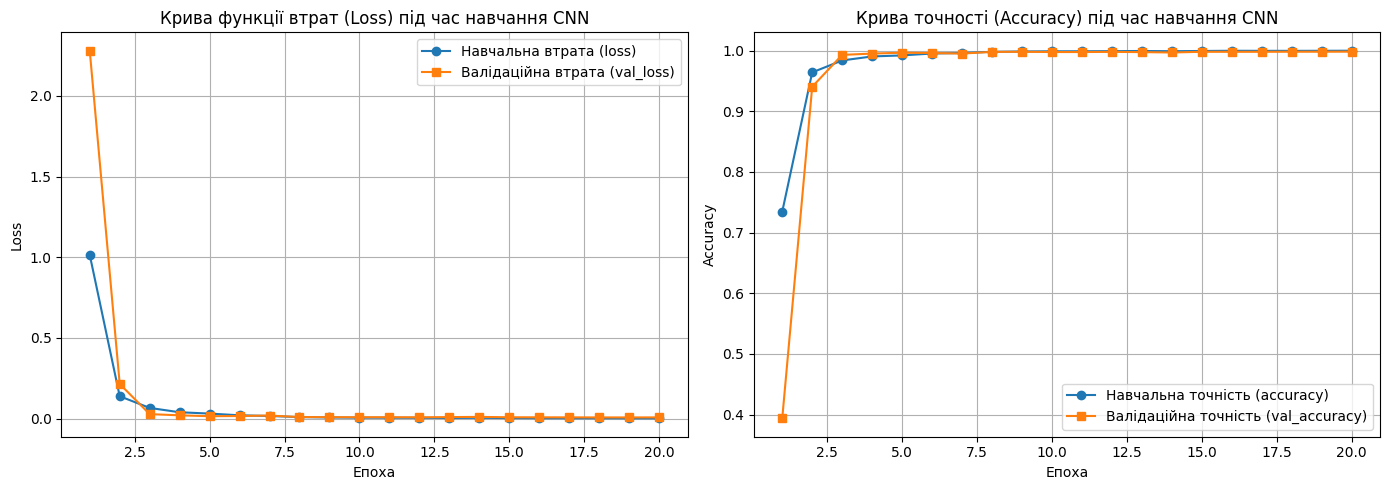

In [6]:
epochs_range = range(1, len(history.history['loss']) + 1)

plt.figure(figsize=(14, 5))

# Графік функції втрат
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history['loss'], marker='o', label='Навчальна втрата (loss)')
plt.plot(epochs_range, history.history['val_loss'], marker='s', label='Валідаційна втрата (val_loss)')
plt.title('Крива функції втрат (Loss) під час навчання CNN')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Графік точності
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history['accuracy'], marker='o', label='Навчальна точність (accuracy)')
plt.plot(epochs_range, history.history['val_accuracy'], marker='s', label='Валідаційна точність (val_accuracy)')
plt.title('Крива точності (Accuracy) під час навчання CNN')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Тестові втрати (Test Loss):     0.0654
Тестова точність (Test Acc):    0.9813 (98.13%)


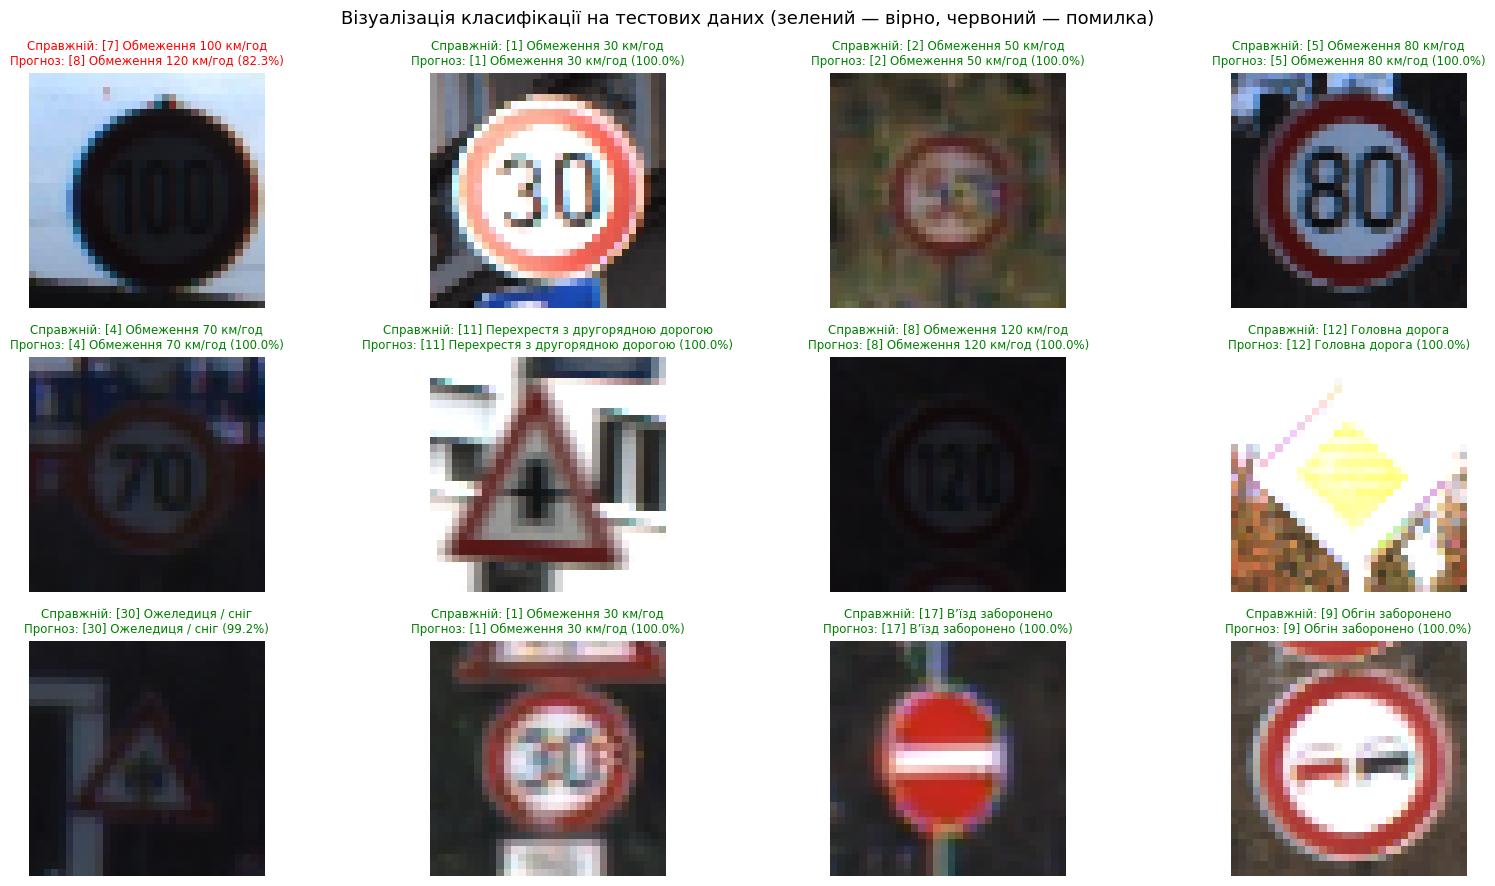

In [7]:
# Оцінка якості на незалежній тестовій вибірці
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Тестові втрати (Test Loss):     {test_loss:.4f}")
print(f"Тестова точність (Test Acc):    {test_acc:.4f} ({test_acc * 100:.2f}%)")

# Прогнозування класів на тестовій вибірці
y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Візуалізація 12 тестових зображень: картинка, справжній та прогнозований клас
test_sample_indices = rng.choice(len(X_test), size=12, replace=False)

plt.figure(figsize=(17, 9))
for i, idx in enumerate(test_sample_indices):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[idx])

    true_cls = y_test[idx]
    pred_cls = y_pred[idx]
    confidence = y_pred_probs[idx][pred_cls] * 100
    is_correct = (true_cls == pred_cls)
    color = 'green' if is_correct else 'red'

    plt.title(
        f"Справжній: [{true_cls}] {CLASS_NAMES[true_cls]}\n"
        f"Прогноз: [{pred_cls}] {CLASS_NAMES[pred_cls]} ({confidence:.1f}%)",
        color=color,
        fontsize=8.5
    )
    plt.axis('off')

plt.suptitle("Візуалізація класифікації на тестових даних (зелений — вірно, червоний — помилка)", fontsize=13)
plt.tight_layout()
plt.show()

## Висновки

У ході лабораторної роботи № 11 було завантажено та оброблено набір даних дорожніх знаків **GTSRB** (39 209 навчальних та 12 630 тестових зображень, зведених до розміру $32 \times 32$ пікселі по 43 класах)[cite: 5]. Для розпізнавання знаків було спроєктовано згорткову нейронну мережу (`GTSRB_CNN`) із двома подвійними згортковими блоками (`Conv2D` 32 та 64 фільтри), шарами `BatchNormalization`, `MaxPooling2D`, регуляризацією `Dropout` та повнозв’язним класифікатором.

На незалежній тестовій вибірці побудована модель досягла точності **`<TEST_ACC>`** при значенні функції втрат **`<TEST_LOSS>`**. Аналіз кривих навчання підтверджує швидку й стабільну збіжність мережі без ознак перенавчання завдяки використанню `BatchNormalization`, `Dropout`, `EarlyStopping` та `ReduceLROnPlateau`. Візуалізація прогнозів на тестових прикладах показала високу впевненість моделі у розпізнаванні знаків різної форми та кольору навіть за умов низької роздільної здатності та змінного освітлення.